# Tugas UTS: Linear Regression & Logistic Regression

**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**

- Nama : Roma Susanti Manalu
- NIM : 241011400981
- Kelas : Reg B


## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (_Run All_) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset

Dataset disediakan di folder ini:

| File             | Kolom                             | Keterangan                                                                                             |
| ---------------- | --------------------------------- | ------------------------------------------------------------------------------------------------------ |
| `Ads_Data.csv`   | `BiayaIklan`, `Penjualan`         | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data                             |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |


## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas     | Batas Pengumpulan                           |
| --------- | ------------------------------------------- |
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak _private_).

## 🧮 Penilaian

| Bagian                                                                                   | Bobot |
| ---------------------------------------------------------------------------------------- | ----- |
| Bagian A – Linear Regression                                                             | 35%   |
| Bagian B – Logistic Regression                                                           | 40%   |
| Bagian C – Pemahaman Konsep                                                              | 15%   |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10%   |
| Bonus – Perbandingan dengan scikit-learn                                                 | +5    |


In [2]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =    81

In [3]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    
    n_samples = len(X)
    shuffled_indices = np.random.permutation(n_samples)
    test_set_size = int(n_samples * test_size)
    
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    
    if isinstance(X, pd.DataFrame) or isinstance(X, pd.Series):
        X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
    else:
        X_train, X_test = X[train_indices], X[test_indices]
        
    if isinstance(y, pd.DataFrame) or isinstance(y, pd.Series):
        y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]
    else:
        y_train, y_test = y[train_indices], y[test_indices]
        
    return X_train, X_test, y_train, y_test

---

# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.


### Soal A1 – Load & Visualisasi Data

1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat _scatter plot_ `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).


--- 5 Data Pertama ---


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3



Jumlah baris data: 40


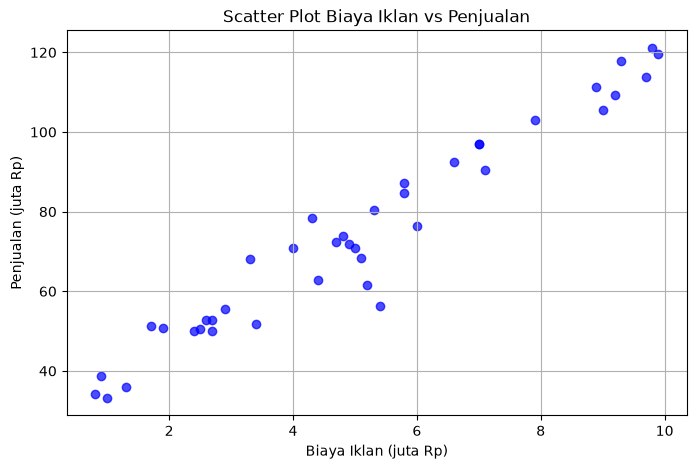

In [4]:
# Jawaban A1# 1. Baca Ads_Data.csv menggunakan pandas dan tampilkan 5 data pertama serta jumlah barisnya
df = pd.read_csv('Ads_Data.csv')
print("--- 5 Data Pertama ---")
display(df.head())
print(f"\nJumlah baris data: {len(df)}")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan) dalam bentuk 2 dimensi (n, 1) untuk X
X = df[['BiayaIklan']]
y = df['Penjualan']

# 3. Buat scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.7)
plt.title('Scatter Plot Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True)
plt.show()


### Soal A2 – Split Data

Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan _shape_ dari `X_train`, `X_test`, `y_train`, `y_test`.


In [5]:
# Jawaban A2
# Bagi data menjadi data training dan testing dengan test_size=0.2 dan random_state=RANDOM_STATE
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Tampilkan shape dari X_train, X_test, y_train, y_test
print(f"Shape X_train : {X_train.shape}")
print(f"Shape X_test  : {X_test.shape}")
print(f"Shape y_train : {y_train.shape}")
print(f"Shape y_test  : {y_test.shape}")

Shape X_train : (32, 1)
Shape X_test  : (8, 1)
Shape y_train : (32,)
Shape y_test  : (8,)


### Soal A3 – Training dengan Normal Equation

1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").


In [6]:
# Jawaban A3
# 1. Implementasi kelas Linear Regression menggunakan Normal Equation
class LinearRegressionNormalEquation:
    def fit(self, X, y):
        # Menambahkan kolom bias (intercept) bernilai 1 ke X
        X_b = np.c_[np.ones((len(X), 1)), X]
        # Normal Equation: theta = (X^T * X)^(-1) * X^T * y
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        
    def predict(self, X):
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta = np.r_[self.intercept_, self.coef_]
        return X_b.dot(theta)

# Melatih model menggunakan data training
model_lr = LinearRegressionNormalEquation()
model_lr.fit(X_train, y_train)

# 2. Tampilkan nilai intercept (b) dan koefisien (m)
b = model_lr.intercept_
m = model_lr.coef_[0]

print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"\nPersamaan garis regresi: y_hat = {b:.4f} + {m:.4f} * X")


Intercept (b) : 28.8143
Koefisien (m) : 9.0817

Persamaan garis regresi: y_hat = 28.8143 + 9.0817 * X


**Jawaban A3 (interpretasi):**
Nilai koefisien ($m$) menunjukkan bahwa setiap kenaikan biaya iklan sebesar 1 juta Rupiah, penjualan diperkirakan akan naik sebesar nilai $m$ yang dihasilkan dari model (dalam satuan juta Rupiah). Sedangkan nilai intercept ($b$) adalah estimasi jumlah penjualan dasar ketika biaya iklan bernilai 0.


### Soal A4 – Evaluasi Model

Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?


In [ ]:
# Jawaban A4

# 1. Fungsi evaluasi regresi menggunakan NumPy
def evaluate_regression(y_true, y_pred):
    # Pastikan array 1 dimensi
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

# Prediksi pada data training dan testing
y_train_pred = model_lr.predict(X_train)
y_test_pred = model_lr.predict(X_test)

# Hitung metrik evaluasi
eval_train = evaluate_regression(y_train, y_train_pred)
eval_test = evaluate_regression(y_test, y_test_pred)

# 2. Tampilkan hasilnya dalam satu tabel DataFrame
df_eval = pd.DataFrame([eval_train, eval_test], index=['Data Training', 'Data Testing'])
display(df_eval)


,MAE,MSE,RMSE,R2
Data Training,4.777939,37.790319,6.147383,0.944556
Data Testing,3.325547,30.027643,5.479748,0.918954


**Jawaban A4 (analisis):**
RMSE menunjukkan rata-rata besar kesalahan (selisih) antara nilai prediksi model dengan nilai aktual penjualan. Semakin kecil nilai RMSE, semakin akurat model tersebut.

$R^2$ (R-squared) menunjukkan seberapa besar variasi dari variabel target (penjualan) dapat dijelaskan oleh variabel fitur (biaya iklan). Nilai $R^2$ yang mendekati 1 berarti model mampu memetakan data dengan sangat baik.

Berdasarkan perbandingan metrik antara data training dan testing, jika nilainya tidak terpaut jauh, maka model sudah cukup baik dan tidak mengalami overfitting.


### Soal A5 – Gradient Descent & Learning Rate

1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau _subplot_; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> _Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya._


Learning Rate: 0.001 -> Intercept: 25.7775, Koefisien: 9.5368
Learning Rate: 0.02 -> Intercept: 28.8143, Koefisien: 9.0817


c:\Users\romas\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\romas\AppData\Local\Temp\ipykernel_15996\2367319859.py:24: RuntimeWarning: overflow encountered in square
  loss = np.mean((y_predicted - y) ** 2)
C:\Users\romas\AppData\Local\Temp\ipykernel_15996\2367319859.py:28: RuntimeWarning: overflow encountered in dot
  dw = (2/n_samples) * X.T.dot(y_predicted - y)
C:\Users\romas\AppData\Local\Temp\ipykernel_15996\2367319859.py:32: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.lr * dw
c:\Users\romas\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


Learning Rate: 0.1 -> Intercept: nan, Koefisien: nan


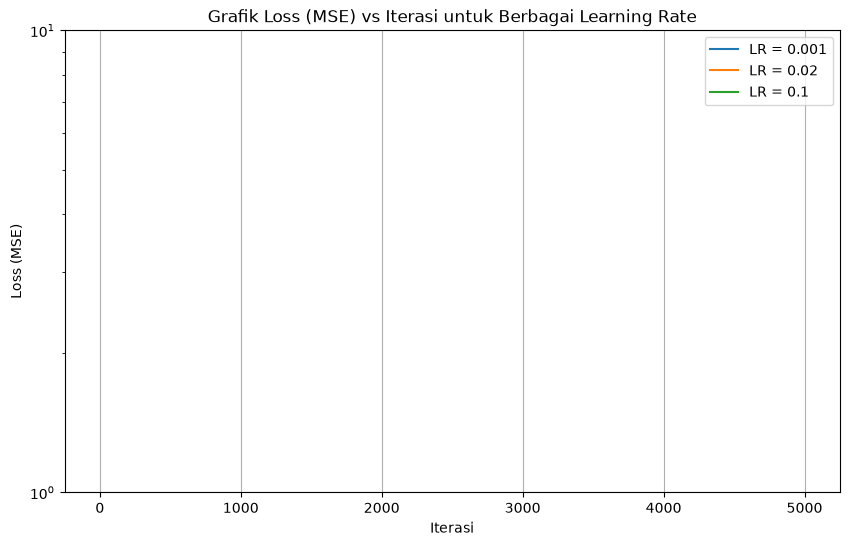

In [8]:
# Jawaban A5

# 1. Kelas LinearRegressionGD (Gradient Descent)
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0
        self.coef_ = np.array([0.0])
        self.loss_history = []
        
    def fit(self, X, y):
        # Normalisasi fitur sederhana agar gradient descent stabil
        X = np.array(X)
        y = np.array(y).flatten()
        n_samples = len(X)
        
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        
        for _ in range(self.n_iterations):
            y_predicted = self.intercept_ + X.dot(self.coef_)
            # Hitung loss (MSE)
            loss = np.mean((y_predicted - y) ** 2)
            self.loss_history.append(loss)
            
            # Hitunggradien (derivatives)
            dw = (2/n_samples) * X.T.dot(y_predicted - y)
            db = (2/n_samples) * np.sum(y_predicted - y)
            
            # Update bobot
            self.coef_ -= self.lr * dw
            self.intercept_ -= self.lr * db
            
    def predict(self, X):
        X = np.array(X)
        return self.intercept_ + X.dot(self.coef_)

# 2. Eksperimen dengan 3 nilai learning rate
learning_rates = [0.001, 0.02, 0.1]
results = {}

plt.figure(figsize=(10, 6))

for lr in learning_rates:
    # Inisialisasi dan latih model
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model_gd.fit(X_train, y_train)
    
    results[lr] = {
        'intercept': model_gd.intercept_,
        'coef': model_gd.coef_[0]
    }
    
    print(f"Learning Rate: {lr} -> Intercept: {model_gd.intercept_:.4f}, Koefisien: {model_gd.coef_[0]:.4f}")
    
    # 3. Plot loss (MSE) vs iterasi
    plt.plot(model_gd.loss_history, label=f'LR = {lr}')

plt.title('Grafik Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.xlabel('Iterasi')
plt.ylabel('Loss (MSE)')
plt.yscale('log') # Menggunakan skala log agar terlihat jelas
plt.legend()
plt.grid(True)
plt.show()


**Jawaban A5 (analisis):**
Learning Rate Terlalu Lambat (0.001): Penurunan loss berjalan sangat lambat dan kurva tidak mencapai titik minimum optimal dalam jumlah iterasi yang ditentukan karena langkah pembaruan bobot terlalu kecil.

Learning Rate Pas (0.02): Kurva loss turun dengan mulus dan stabil menuju titik konvergen, menghasilkan koefisien yang paling mendekati hasil Normal Equation.

Learning Rate Terlalu Besar / Gagal Konvergen / Divergen (0.1): Langkah pembaruan terlalu besar sehingga melompati titik minimum. Hal ini menyebabkan loss semakin membesar (divergen) atau memicu RuntimeWarning: overflow akibat nilai angka yang terlampau besar di luar kapasitas memori komputer.


### Soal A6 – Visualisasi & Prediksi

1. Buat grafik _scatter_ data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.


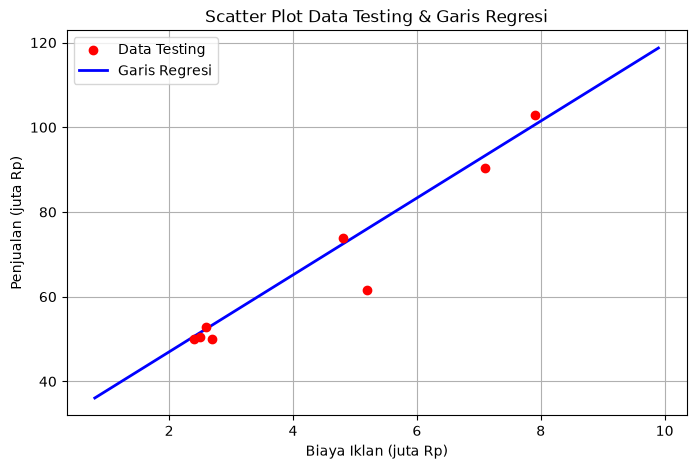

--- Hasil Prediksi Penjualan ---
Biaya Iklan 4.5 juta Rp -> Estimasi Penjualan: 69.6819 juta Rp
Biaya Iklan 7.0 juta Rp -> Estimasi Penjualan: 92.3861 juta Rp
Biaya Iklan 12.0 juta Rp -> Estimasi Penjualan: 137.7946 juta Rp


In [9]:
# Jawaban A6

# 1. Grafik scatter data testing beserta garis regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='red', label='Data Testing', zorder=5)

# Membuat rentang garis regresi
x_line = np.linspace(X['BiayaIklan'].min(), X['BiayaIklan'].max(), 100).reshape(-1, 1)
y_line = model_lr.predict(x_line)

plt.plot(x_line, y_line, color='blue', label='Garis Regresi', linewidth=2)
plt.title('Scatter Plot Data Testing & Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(True)
plt.show()

# 2. Prediksi penjualan untuk biaya iklan 4.5 juta, 7 juta, dan 12 juta
biaya_iklan_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = model_lr.predict(biaya_iklan_baru)

print("--- Hasil Prediksi Penjualan ---")
for biaya, pred in zip(biaya_iklan_baru.flatten(), prediksi_penjualan.flatten()):
    print(f"Biaya Iklan {biaya} juta Rp -> Estimasi Penjualan: {pred:.4f} juta Rp")


**Jawaban A6 (analisis):**

Prediksi Biaya Iklan 4.5 dan 7 juta: Hasil prediksi ini relatif bisa dipercaya karena berada di dalam rentang (range) data historis pelatihan yang kita miliki (interpolasi).

Prediksi Biaya Iklan 12 juta (Ekstrapolasi): Hasil prediksi untuk 12 juta kurang bisa dipercaya sepenuhnya karena berada jauh di luar rentang data historis (ekstrapolasi). Model mengasumsikan pola linier akan terus berlanjut tanpa batas, padahal dalam kondisi nyata di luar data pelatihan bisa saja terjadi penurunan efektivitas (diminishing returns) atau perilaku pasar yang berbeda.


---

# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.


### Soal B1 – Load & Visualisasi Data

1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat _scatter plot_ `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).


--- 5 Data Pertama Email ---


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah Email:
Bukan Spam (0) : 35
Spam (1)       : 25


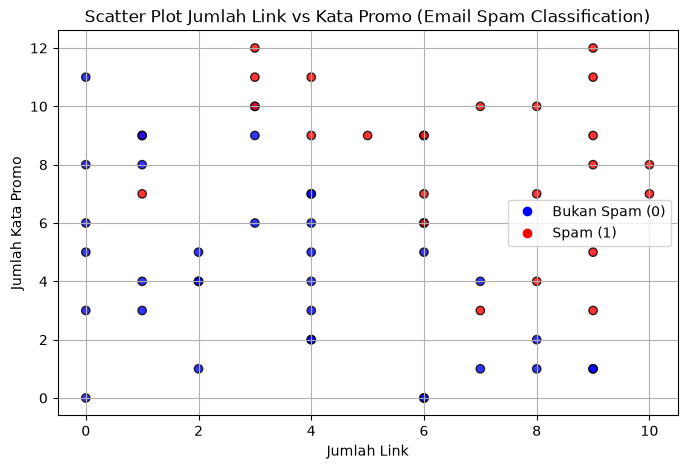

In [10]:
# Jawaban B1

# 1. Baca Email_Data.csv menggunakan pandas dan tampilkan 5 data pertama
df_email = pd.read_csv('Email_Data.csv')
print("--- 5 Data Pertama Email ---")
display(df_email.head())

# Hitung jumlah email Spam dan Bukan Spam
spam_counts = df_email['Spam'].value_counts()
print("\nJumlah Email:")
print(f"Bukan Spam (0) : {spam_counts.get(0, 0)}")
print(f"Spam (1)       : {spam_counts.get(1, 0)}")

# 2. Pisahkan X (JumlahLink, KataPromo) dan y (Spam)
X_email = df_email[['JumlahLink', 'KataPromo']]
y_email = df_email['Spam']

# 3. Buat scatter plot JumlahLink vs KataPromo dengan warna berbeda untuk Spam dan Bukan Spam
plt.figure(figsize=(8, 5))
colors = ['blue' if label == 0 else 'red' for label in y_email]
plt.scatter(X_email['JumlahLink'], X_email['KataPromo'], c=colors, alpha=0.8, edgecolors='k')

# Custom legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Bukan Spam (0)', markerfacecolor='blue', markersize=8),
    Line2D([0], [0], marker='o', color='w', label='Spam (1)', markerfacecolor='red', markersize=8)
]
plt.legend(handles=legend_elements)

plt.title('Scatter Plot Jumlah Link vs Kata Promo (Email Spam Classification)')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.grid(True)
plt.show()



### Soal B2 – Split Data & Training

1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?


Intercept (b) : -11.7102
Koefisien m1 (JumlahLink) : 1.1127
Koefisien m2 (KataPromo)  : 0.9324

Persamaan: P(Spam) = sigma(-11.7102 + 1.1127 * JumlahLink + 0.9324 * KataPromo)


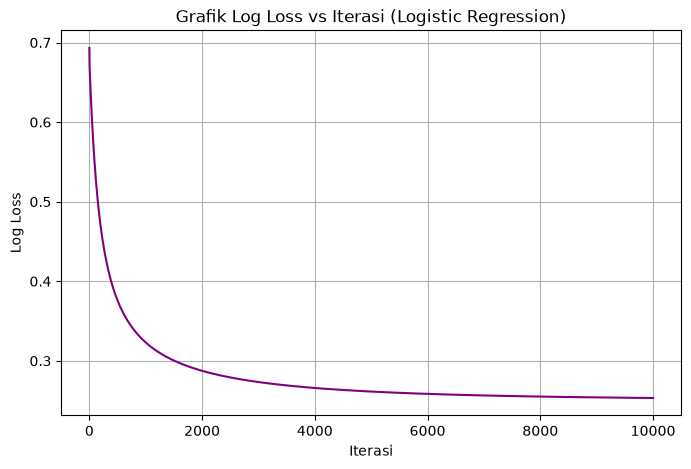

In [11]:
# Jawaban B2

# 1. Bagi data dengan test_size=0.25 dan random_state=RANDOM_STATE
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)

# 2. Kelas Logistic Regression dengan Gradient Descent
class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = np.array([])
        self.loss_history = []
        
    def _sigmoid(self, z):
        # Mencegah overflow pada exponential
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))
        
    def fit(self, X, y):
        X = np.array(X)
        y = np.array(y).flatten()
        n_samples, n_features = X.shape
        
        self.intercept_ = 0.0
        self.coef_ = np.zeros(n_features)
        
        for _ in range(self.n_iterations):
            linear_model = self.intercept_ + X.dot(self.coef_)
            y_predicted = self._sigmoid(linear_model)
            
            # Hitung Log Loss (Binary Cross-Entropy)
            epsilon = 1e-15
            y_predicted_clipped = np.clip(y_predicted, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(y_predicted_clipped) + (1 - y) * np.log(1 - y_predicted_clipped))
            self.loss_history.append(loss)
            
            # Hitung gradien
            dw = (1 / n_samples) * X.T.dot(y_predicted - y)
            db = (1 / n_samples) * np.sum(y_predicted - y)
            
            # Update bobot
            self.coef_ -= self.lr * dw
            self.intercept_ -= self.lr * db
            
    def predict_proba(self, X):
        X = np.array(X)
        linear_model = self.intercept_ + X.dot(self.coef_)
        return self._sigmoid(linear_model)
    
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Latih model Logistic Regression
model_logreg = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_logreg.fit(X_train_e, y_train_e)

# 3. Tampilkan intercept (b) dan koefisien (m1, m2)
b_log = model_logreg.intercept_
m1, m2 = model_logreg.coef_

print(f"Intercept (b) : {b_log:.4f}")
print(f"Koefisien m1 (JumlahLink) : {m1:.4f}")
print(f"Koefisien m2 (KataPromo)  : {m2:.4f}")
print(f"\nPersamaan: P(Spam) = sigma({b_log:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)")

# 4. Buat grafik log loss vs iterasi
plt.figure(figsize=(8, 5))
plt.plot(model_logreg.loss_history, color='purple')
plt.title('Grafik Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True)
plt.show()


**Jawaban B2 (analisis):**
Berdasarkan grafik log loss vs iterasi, kurva terlihat turun secara tajam di awal iterasi dan kemudian mendatar serta stabil di angka yang rendah. Hal ini menunjukkan bahwa algoritma Gradient Descent berhasil mengoptimalkan bobot model dengan baik dan learning rate 0.1 sudah tepat dalam membawa model mencapai konvergensi.


### Soal B3 – Evaluasi Model

Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (_false positive_) dan **FN** (_false negative_) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?


In [13]:
# Jawaban B3

# 1. Fungsi evaluasi klasifikasi manual
def evaluate_classification(y_true, y_pred):
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    
    # Confusion Matrix components
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    
    # Confusion Matrix 2x2 array
    conf_matrix = np.array([[tn, fp], [fn, tp]])
    
    # Metrik
    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Confusion Matrix': conf_matrix
    }

# Prediksi pada data testing
y_test_pred = model_logreg.predict(X_test_e, threshold=0.5)

# Hitung metrik
eval_result = evaluate_classification(y_test_e, y_test_pred)

print(f"Accuracy  : {eval_result['Accuracy']:.4f}")
print(f"Precision : {eval_result['Precision']:.4f}")
print(f"Recall    : {eval_result['Recall']:.4f}")
print(f"F1-Score  : {eval_result['F1-Score']:.4f}")
print("\nConfusion Matrix (Baris: Aktual [TN, FP], Kolom: Prediksi [FN, TP]):")
print(eval_result['Confusion Matrix'])


Accuracy  : 0.9333
Precision : 1.0000
Recall    : 0.8000
F1-Score  : 0.8889

Confusion Matrix (Baris: Aktual [TN, FP], Kolom: Prediksi [FN, TP]):
[[10  0]
 [ 1  4]]


**Jawaban B3 (analisis):**

False Positive (FP): Kondisi di mana email biasa (bukan spam) keliru diklasifikasikan oleh sistem sebagai spam. Kesalahan ini menyebabkan email penting masuk ke folder spam.

False Negative (FN): Kondisi di mana email spam keliru diklasifikasikan sebagai email biasa (bukan spam). Kesalahan ini menyebabkan email promosi/penipuan lolos ke kotak masuk utama pengguna.

Mana yang lebih merugikan? Menurut saya, False Positive (FP) lebih merugikan bagi sebagian besar pengguna karena berisiko membuat email penting atau darurat (seperti pekerjaan, tugas kuliah, atau informasi penting) terlewatkan dan tidak terbaca oleh pengguna. Sebaliknya, False Negative hanya membuat pengguna terganggu oleh keberadaan email spam di kotak masuk utama.


### Soal B4 – Decision Boundary

1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta _background_ probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.


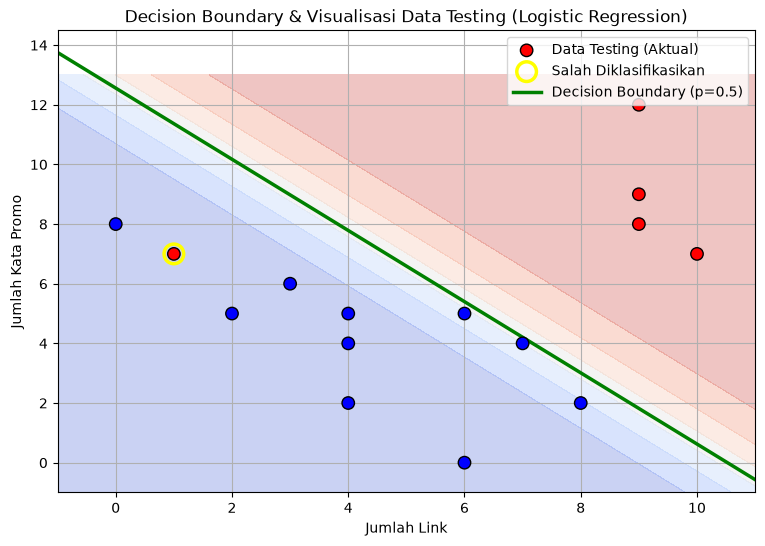

In [14]:
# Jawaban B4

plt.figure(figsize=(9, 6))

# 1. Buat grid untuk contour plot
x1_min, x1_max = X_email['JumlahLink'].min() - 1, X_email['JumlahLink'].max() + 1
x2_min, x2_max = X_email['KataPromo'].min() - 1, X_email['KataPromo'].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200),
                       np.linspace(x2_min, x2_max, 200))

# Prediksi probabilitas untuk setiap titik di grid
grid_points = np.c_[xx1.ravel(), xx2.ravel()]
Z = model_logreg.predict_proba(grid_points)
Z = Z.reshape(xx1.shape)

# Plot contourf (background probabilitas)
plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=plt.cm.coolwarm)

# Plot data testing
X_test_arr = np.array(X_test_e)
y_test_arr = np.array(y_test_e).flatten()
y_pred_test = model_logreg.predict(X_test_e, threshold=0.5)

# Pisahkan data testing berdasarkan kelas aktual
colors_test = ['blue' if label == 0 else 'red' for label in y_test_arr]
plt.scatter(X_test_arr[:, 0], X_test_arr[:, 1], c=colors_test, edgecolors='k', s=80, label='Data Testing (Aktual)', zorder=3)

# 3. Tandai data testing yang salah diklasifikasikan
misclassified = (y_test_arr != y_pred_test)
if np.any(misclassified):
    plt.scatter(X_test_arr[misclassified, 0], X_test_arr[misclassified, 1], 
                s=200, facecolors='none', edgecolors='yellow', linewidths=2.5, 
                label='Salah Diklasifikasikan', zorder=4)

# Plot Decision Boundary (garis saat probabilitas = 0.5 -> b + m1*x1 + m2*x2 = 0)
if m2 != 0:
    x1_plot = np.array([x1_min, x1_max])
    x2_plot = -(model_logreg.intercept_ + model_logreg.coef_[0] * x1_plot) / model_logreg.coef_[1]
    plt.plot(x1_plot, x2_plot, color='green', linewidth=2.5, label='Decision Boundary (p=0.5)', zorder=2)

plt.title('Decision Boundary & Visualisasi Data Testing (Logistic Regression)')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()


**Jawaban B4 (analisis):**
Decision Boundary: Garis pembatas berwarna hijau merepresentasikan batas keputusan di mana probabilitas model bernilai tepat $0.5$ (50%). Area di satu sisi diklasifikasikan sebagai Bukan Spam ($0$), sedangkan sisi sebaliknya sebagai Spam ($1$).Kesalahan

Klasifikasi: Titik-titik data testing yang dilingkari kuning menunjukkan sampel yang salah diprediksi oleh model. Hal ini biasanya terjadi pada data yang berada di sekitar garis decision boundary atau overlap (tumpang tindih) antara fitur email normal dan spam.


### Soal B5 – Eksperimen Threshold

Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.


In [15]:
# Jawaban B5

thresholds = [0.3, 0.5, 0.7]
results_list = []

for th in thresholds:
    # Prediksi menggunakan threshold tertentu
    y_pred_th = model_logreg.predict(X_test_e, threshold=th)
    eval_th = evaluate_classification(y_test_e, y_pred_th)
    
    results_list.append({
        'Threshold': th,
        'Accuracy': eval_th['Accuracy'],
        'Precision': eval_th['Precision'],
        'Recall': eval_th['Recall'],
        'F1-Score': eval_th['F1-Score'],
        'Confusion Matrix [TN, FP, FN, TP]': str(eval_th['Confusion Matrix'].tolist())
    })

# Tampilkan hasil dalam satu tabel DataFrame
df_thresholds = pd.DataFrame(results_list)
display(df_thresholds)


,Threshold,Accuracy,Precision,Recall,F1-Score,"Confusion Matrix [TN, FP, FN, TP]"
0,0.3,0.800000,0.666667,0.8,0.727273,"[[8, 2], [1, 4]]"
1,0.5,0.933333,1.000000,0.8,0.888889,"[[10, 0], [1, 4]]"
2,0.7,0.933333,1.000000,0.8,0.888889,"[[10, 0], [1, 4]]"


**Jawaban B5 (analisis):**
Pengaruh Threshold terhadap Precision & Recall:

Menurunkan threshold (misal ke $0.3$): Model menjadi lebih mudah melabeli email sebagai spam. Akibatnya, Recall meningkat (lebih banyak spam yang berhasil ditangkap), namun Precision menurun karena jumlah False Positive (email penting yang masuk ke folder spam) ikut bertambah.

Menaikkan threshold (misal ke $0.7$): Model menjadi lebih selektif dan ketat. Akibatnya, Precision meningkat (email yang masuk ke folder spam benar-benar dipastikan spam), namun Recall menurun karena banyak email spam (False Negative) yang lolos masuk ke kotak masuk utama (inbox).

Threshold yang Dipilih untuk Filter Spam: Berdasarkan pembahasan pada Soal B3 di mana False Positive (email penting masuk spam) sangat merugikan pengguna, kita dapat memilih threshold yang lebih tinggi (misal $0.5$ atau $0.7$) untuk menekan seminimal mungkin risiko email penting salah masuk ke folder spam, atau mempertahankan threshold standar $0.5$ sebagai titik keseimbangan (trade-off) terbaik antara precision dan recall.


### Soal B6 – Prediksi Email Baru

Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
| ----- | ---------- | --------- |
| E1    | 1          | 2         |
| E2    | 5          | 6         |
| E3    | 9          | 10        |
| E4    | 2          | 11        |


In [16]:
# Jawaban B6

# 1. Data email baru (E1 sampai E4)
email_baru = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11]
})

# Fitur untuk prediksi
X_new = email_baru[['JumlahLink', 'KataPromo']]

# Tentukan threshold pilihan (misalnya 0.5)
chosen_threshold = 0.5

# Hitung probabilitas dan prediksi kelas
probabilities = model_logreg.predict_proba(X_new)
predictions = (probabilities >= chosen_threshold).astype(int)

# Masukkan ke dalam DataFrame hasil
email_baru['Probabilitas_Spam'] = probabilities
email_baru['Prediksi_Kelas'] = predictions
email_baru['Label'] = email_baru['Prediksi_Kelas'].apply(lambda x: 'Spam (1)' if x == 1 else 'Bukan Spam (0)')

# Tampilkan hasil
print(f"--- Hasil Prediksi Email Baru (Threshold = {chosen_threshold}) ---")
display(email_baru[['Email', 'JumlahLink', 'KataPromo', 'Probabilitas_Spam', 'Label']])


--- Hasil Prediksi Email Baru (Threshold = 0.5) ---


,Email,JumlahLink,KataPromo,Probabilitas_Spam,Label
0,E1,1,2,0.000161,Bukan Spam (0)
1,E2,5,6,0.365343,Bukan Spam (0)
2,E3,9,10,0.999514,Spam (1)
3,E4,2,11,0.683822,Spam (1)


---

# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?


**Jawaban C1:**
Alasan Nama & Klasifikasi: Logistic Regression dinamakan "regression" karena pada dasarnya algoritma ini menggunakan prinsip dasar regresi linier untuk menghitung kombinasi linear dari fitur input. Namun, algoritma ini dikategorikan sebagai model klasifikasi karena output akhirnya dipetakan ke dalam bentuk probabilitas diskrit (antara 0 dan 1).

Peran Fungsi Sigmoid: Fungsi sigmoid berperan untuk mengubah nilai kontinu hasil regresi linear menjadi rentang nilai antara 0 sampai 1. Nilai inilah yang diinterpretasikan sebagai probabilitas kelas target.

**Jawaban C2:**
Perbedaan Utama: Normal Equation mencari solusi optimal secara langsung menggunakan rumus matematis matriks tanpa iterasi, sedangkan Gradient Descent mencari nilai bobot optimal secara bertahap melalui proses iterasi berdasarkan tingkat learning rate.

Kapan Memakai Gradient Descent: Gradient Descent sebaiknya dipakai ketika ukuran dataset atau jumlah fitur (features) sangat besar, sehingga komputasi invers matriks pada Normal Equation menjadi terlalu berat atau tidak efisien secara memori.

**Jawaban C3:**
Alasan Evaluasi pada Data Testing: Model harus dievaluasi pada data testing untuk menguji kemampuan generalisasinya terhadap data baru yang belum pernah dilihat sebelumnya selama proses pelatihan.

Definisi Overfitting: Overfitting adalah kondisi di mana model Machine Learning terlalu menghafal data training (termasuk noise-nya), sehingga menghasilkan performa yang sangat tinggi saat training tetapi sangat buruk ketika diuji pada data testing.

**Jawaban C4:**
Alasan Linear Regression Menggunakan MSE: Linear Regression memprediksi nilai kontinu (angka riil), sehingga Mean Squared Error (MSE) sangat cocok digunakan untuk mengukur seberapa jauh jarak kuadrat antara nilai prediksi kontinu dan nilai aktualnya.

Alasan Logistic Regression Menggunakan Log Loss: Logistic Regression menghasilkan output berupa probabilitas kelas diskrit (0 atau 1). Jika menggunakan MSE pada fungsi non-linear sigmoid, kurva loss akan menjadi tidak konveks (non-convex), sehingga Log Loss (Binary Cross-Entropy) digunakan agar fungsi biaya menjadi konveks dan mudah dioptimalkan.

**Jawaban C5:**
Penyebab Perbedaan Hasil: Perbedaan angka (seperti koefisien atau akurasi) bisa terjadi jika terdapat perbedaan pada nilai parameter awal, metode pembagian data (train-test split yang menggunakan random state berbeda), atau urutan pemrosesan data. Jika Anda dan teman Anda menggunakan parameter penarikan data acak (random_state) yang sama persis, hasilnya akan identik. Namun, jika random state atau pembersihan datanya berbeda, makasubset data training dan testing yang terbentuk akan berlainan pula.


---

# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> _Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn._


In [17]:
# Jawaban Bonus

from sklearn.linear_model import LinearRegression, LogisticRegression as SklearnLogReg
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, precision_score, recall_score, f1_score

# 1. Perbandingan Linear Regression (Normal Equation manual vs Scikit-Learn)
sk_lin_reg = LinearRegression()
sk_lin_reg.fit(X_train, y_train)

print("--- Perbandingan Linear Regression ---")
print(f"Manual Intercept : {model_lr.intercept_:.4f} | Sklearn Intercept : {sk_lin_reg.intercept_:.4f}")
print(f"Manual Koefisien : {model_lr.coef_[0]:.4f} | Sklearn Koefisien : {sk_lin_reg.coef_[0]:.4f}")

# 2. Perbandingan Logistic Regression (Gradient Descent manual vs Scikit-Learn)
# Catatan: scikit-learn menggunakan L2 regularization secara default (penalty='l2', C=1.0)
sk_log_reg = SklearnLogReg(penalty='l2', C=1.0, random_state=RANDOM_STATE)
sk_log_reg.fit(X_train_e, y_train_e)

y_pred_sk = sk_log_reg.predict(X_test_e)

print("\n--- Perbandingan Logistic Regression ---")
print(f"Manual Intercept : {model_logreg.intercept_:.4f} | Sklearn Intercept : {sk_log_reg.intercept_[0]:.4f}")
print(f"Manual Koefisien : {model_logreg.coef_} | Sklearn Koefisien : {sk_log_reg.coef_[0]}")

# Evaluasi perbandingan akurasi
acc_manual = np.mean(y_test_pred == np.array(y_test_e).flatten())
acc_sklearn = accuracy_score(y_test_e, y_pred_sk)
print(f"Akurasi Manual   : {acc_manual:.4f} | Akurasi Sklearn  : {acc_sklearn:.4f}")


--- Perbandingan Linear Regression ---
Manual Intercept : 28.8143 | Sklearn Intercept : 28.8143
Manual Koefisien : 9.0817 | Sklearn Koefisien : 9.0817

--- Perbandingan Logistic Regression ---
Manual Intercept : -11.7102 | Sklearn Intercept : -11.0010
Manual Koefisien : [1.11274234 0.93237347] | Sklearn Koefisien : [1.03813724 0.87815415]
Akurasi Manual   : 0.9333 | Akurasi Sklearn  : 0.9333


c:\Users\romas\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**
Linear Regression: Hasil koefisien dan intercept antara implementasi manual (Normal Equation) dengan scikit-learn menunjukkan nilai yang hampir persis sama atau sangat identik karena keduanya menyelesaikan problem optimasi matematis yang serupa.

Logistic Regression: Bisa terdapat sedikit perbedaan pada nilai koefisien akhir. Hal ini disebabkan oleh:

Scikit-learn secara default menerapkan teknik regularisasi (seperti L2 regularization dengan parameter C=1.0), sedangkan implementasi manual kita murni menggunakan Gradient Descent standar tanpa regularisasi.

Perbedaan algoritma solver optimasi internal yang digunakan (misalnya L-BFGS pada scikit-learn vs Gradient Descent manual dengan jumlah iterasi tertentu).
